# 01. 탐색적 데이터 분석 (EDA)

제주 감귤 생산·유통·가격 데이터의 구조와 품질을 파악하고, 요구사항 **FR-201(트렌드)**, **FR-202(규격·시장 프리미엄)** 분석의 출발점을 만듭니다.

| 섹션 | 데이터 | 관련 요구사항 |
| --- | --- | --- |
| 1. 데이터 개요 | 전체 | FR-102 |
| 2. 노지온주 연도별 추이 | `noji_yearly` | FR-201 |
| 3. 2025년산 월별 출하·가격 | `noji_monthly_2025` | FR-201 |
| 4. 규격(크기)별 가격·비율 | `noji_size` | FR-202 |
| 5. 도매시장별 거래량·가격 | `noji_market_2025` | FR-202 |
| 6. 품종별 유통 비교 | `varieties_summary` | FR-201 |
| 7. 과수 생산량 추이 | `raw/fruit_production` | FR-201 |
| 8. 제주 특용작물 | `jeju_special_crops` | 참고 |
| 9. 정리 및 다음 단계 | - | - |

> 커널: **Python 3.10 (jeju_citrus)**

## 0. 환경 설정

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns

from jeju_citrus.config import FIGURES_DIR
from jeju_citrus.data import load_processed, load_raw
from jeju_citrus.data.loader import PROCESSED_DATASETS
from jeju_citrus.data.preprocess import drop_total_rows, parse_crop_year
from jeju_citrus.visualization import set_style

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.1f}".format)

SAVE_FIG = False  # True로 바꾸면 reports/figures/에 그래프 저장


def savefig(name: str) -> None:
    if SAVE_FIG:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)


comma = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

## 1. 데이터 개요

모든 데이터셋의 크기, 결측치, 자료형을 한눈에 확인합니다.

In [2]:
dfs = {name: load_processed(name) for name in PROCESSED_DATASETS}
dfs["fruit_production"] = load_raw("fruit_production.csv")

overview = pd.DataFrame(
    {
        "행": {k: v.shape[0] for k, v in dfs.items()},
        "열": {k: v.shape[1] for k, v in dfs.items()},
        "결측치": {k: int(v.isna().sum().sum()) for k, v in dfs.items()},
        "중복행": {k: int(v.duplicated().sum()) for k, v in dfs.items()},
        "설명": {**PROCESSED_DATASETS, "fruit_production": "제주 과수 생산량 통계 (2015~2020)"},
    }
)
overview

,행,열,결측치,중복행,설명
jeju_special_crops,758,8,6,1,제주 특용작물 생산현황 (전국 데이터에서 제주만 추출)
noji_yearly,5,5,0,0,노지온주 5개년 연도별 처리량·단가·조수입
noji_monthly_2025,7,6,0,0,2025년산 노지온주 월별 출하량·가격
noji_market_2025,9,5,0,0,2025년산 노지온주 도매시장별 거래량·가격
noji_size,15,5,0,0,최근 3개년 노지온주 규격(2S~2L)별 가격·비율
varieties_summary,19,10,0,0,품종별(하우스/월동/만감류) 유통처리 비교
citrus_production_yearly,137,12,0,0,8개 품종 연도별 재배면적·생산량·조수입·농가수·단가 (2004~2025)
citrus_processing_yearly,22,6,20,0,연도별 총처리량·가공처리량·가공률·수매단가 (2004~2025)
citrus_processing_by_company,154,3,46,0,연도별·가공업체별 가공처리량 (2004~2025)
citrus_export_yearly,229,4,2,0,연도별·국가별 수출량·수출액 (2003~2025)


In [3]:
for name, df in dfs.items():
    print(f"■ {name}  {df.shape}")
    print(df.dtypes.to_string(), end="\n\n")

■ jeju_special_crops  (758, 8)
기준 연도           int64
시도             object
품명             object
농가수[호]          int64
재배면적[ha]        int64
수확면적[ha]        int64
단수[kg/10a]    float64
생산량[M/T]      float64

■ noji_yearly  (5, 5)
품종구분       object
연도         object
처리량_톤       int64
단가_원_kg     int64
조수입_백만원     int64

■ noji_monthly_2025  (7, 6)
품종구분         object
산지연도         object
월구분          object
출하량_톤         int64
최고가_원_5kg     int64
평균가_원_5kg     int64

■ noji_market_2025  (9, 5)
품종구분         object
산지연도         object
도매시장         object
거래량_톤         int64
평균가_원_5kg     int64

■ noji_size  (15, 5)
품종구분          object
산지연도          object
크기구분          object
평균가_원_5kg      int64
거래비율_퍼센트     float64

■ varieties_summary  (19, 10)
대분류              object
세부품종             object
처리량_2025_톤      float64
단가_2025_원_kg      int64
조수입_2025_백만원      int64
처리량_2024_톤      float64
단가_2024_원_kg      int64
조수입_2024_백만원      int64
처리량_증감률_퍼센트       int64
조수입_증감률_퍼센트       int64

■ ci

**📝 관찰**
- 대부분의 데이터셋은 결측치·중복행이 없습니다. 예외는 `jeju_special_crops`로, **단수 결측치 6건과 중복행 1건**이 있습니다(8절에서 확인).
- `연도`, `산지연도`가 `'2025년산'` 같은 **문자열**이라 정렬이나 시계열 분석 전에 정수로 바꿔야 합니다. → `parse_crop_year()`
- `계`, `소계` 같은 **합계 행**이 개별 항목과 섞여 있습니다. 그대로 집계하면 두 번 더해집니다. → `drop_total_rows()`

## 2. 노지온주 연도별 추이 (FR-201)

처리량(톤), 단가(원/kg), 조수입(백만원)의 5개년 흐름입니다.

In [4]:
yearly = dfs["noji_yearly"].copy()
yearly["연도"] = parse_crop_year(yearly["연도"])
yearly = yearly.sort_values("연도").reset_index(drop=True)

# 전년 대비 증감률(%)
for col in ["처리량_톤", "단가_원_kg", "조수입_백만원"]:
    yearly[f"{col}_YoY%"] = yearly[col].pct_change() * 100
yearly

,품종구분,연도,처리량_톤,단가_원_kg,조수입_백만원,처리량_톤_YoY%,단가_원_kg_YoY%,조수입_백만원_YoY%
0,노지온주,2021,467293,1043,487293,NaN,NaN,NaN
1,노지온주,2022,428977,1141,489649,-8.2,9.4,0.5
2,노지온주,2023,398246,1590,633398,-7.2,39.4,29.4
3,노지온주,2024,369145,1779,656829,-7.3,11.9,3.7
4,노지온주,2025,410965,1701,698979,11.3,-4.4,6.4


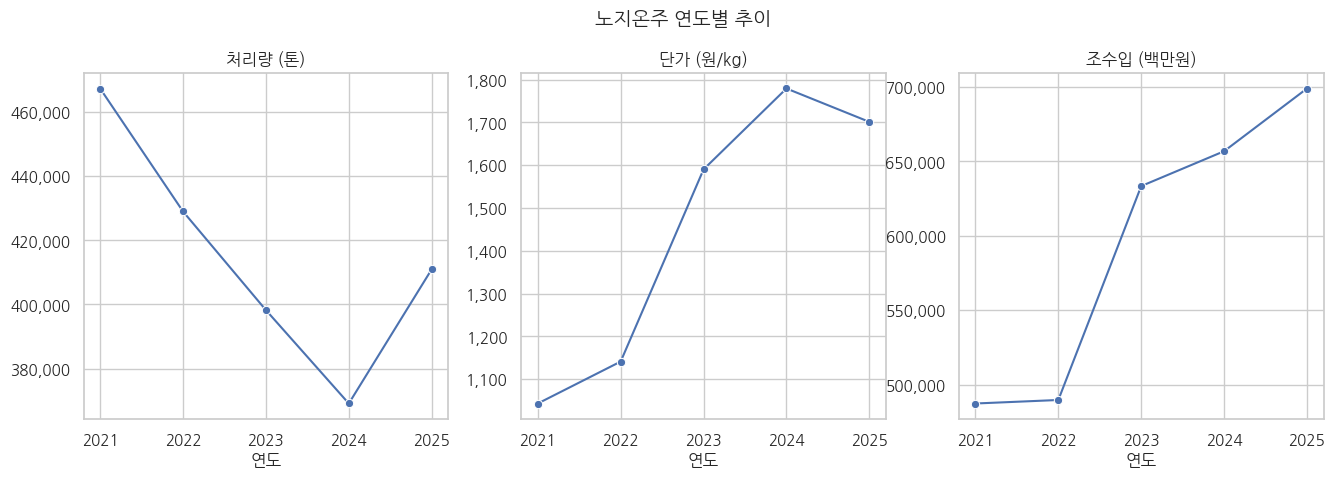

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
specs = [("처리량_톤", "처리량 (톤)"), ("단가_원_kg", "단가 (원/kg)"), ("조수입_백만원", "조수입 (백만원)")]
for ax, (col, title) in zip(axes, specs):
    sns.lineplot(data=yearly, x="연도", y=col, marker="o", ax=ax)
    ax.set_title(title)
    ax.set_xticks(yearly["연도"])
    ax.yaxis.set_major_formatter(comma)
    ax.set_ylabel("")
fig.suptitle("노지온주 연도별 추이", fontsize=14, y=1.02)
savefig("noji_yearly_trend")
plt.show()

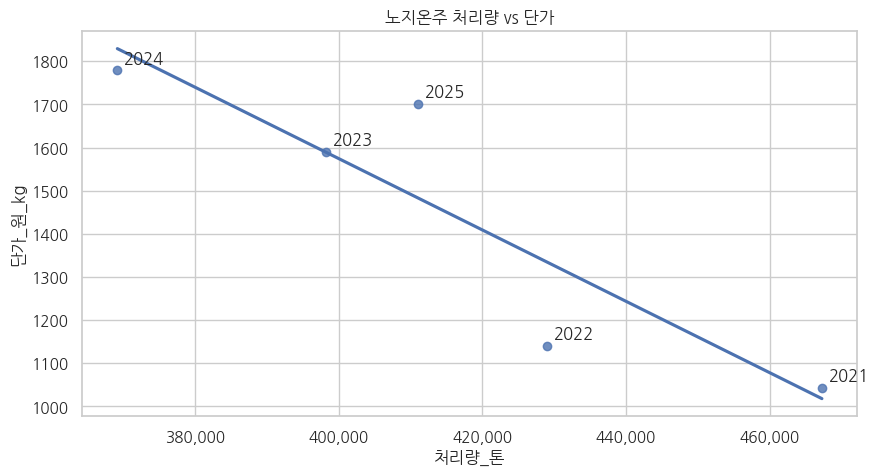

상관계수(처리량, 단가): -0.90  (n=5, 참고용)


In [6]:
# 처리량과 단가의 관계: 공급이 늘면 가격이 떨어지는가?
ax = sns.regplot(data=yearly, x="처리량_톤", y="단가_원_kg", ci=None)
for _, r in yearly.iterrows():
    ax.annotate(int(r["연도"]), (r["처리량_톤"], r["단가_원_kg"]), xytext=(5, 5), textcoords="offset points")
ax.xaxis.set_major_formatter(comma)
ax.set_title("노지온주 처리량 vs 단가")
plt.show()

print(f"상관계수(처리량, 단가): {yearly['처리량_톤'].corr(yearly['단가_원_kg']):.2f}  (n=5, 참고용)")

**📝 관찰**
- 처리량은 2021년 약 46.7만 톤에서 2024년 약 36.9만 톤으로 줄었다가, 2025년 약 41.1만 톤으로 다시 늘었습니다.
- 단가는 2021년 1,043원/kg에서 2024년 1,779원/kg으로 **70% 넘게 올랐습니다.** 공급이 줄면 가격이 오르는 역의 관계가 뚜렷합니다.
- 2025년에는 처리량이 늘었는데도 단가가 크게 떨어지지 않아(1,701원/kg) **조수입이 역대 최고**를 기록했습니다.
- ⚠️ 표본이 5개뿐이라 상관계수는 참고만 해야 합니다. 수급 예측(FR-203 이후)에는 기상 데이터 같은 장기 시계열이 필요합니다.

**❓ 같이 볼 질문**: 2025년산의 가격 방어는 품질(당도·규격) 덕분일까요, 다른 품종의 공급 감소 덕분일까요?

## 3. 2025년산 노지온주 월별 출하·가격 (FR-201)

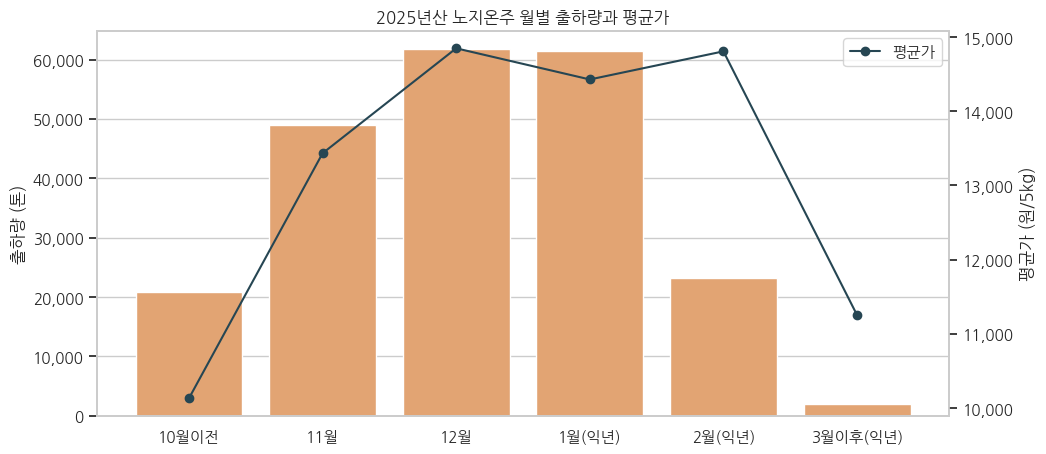

,품종구분,산지연도,월구분,출하량_톤,최고가_원_5kg,평균가_원_5kg,출하비중_퍼센트
0,노지온주,2025년산,10월이전,20821,60200,10131,9.5
1,노지온주,2025년산,11월,48944,73300,13434,22.4
2,노지온주,2025년산,12월,61748,66700,14849,28.3
3,노지온주,2025년산,1월(익년),61423,83300,14429,28.1
4,노지온주,2025년산,2월(익년),23260,61700,14808,10.7
5,노지온주,2025년산,3월이후(익년),2040,56700,11253,0.9


In [7]:
monthly = drop_total_rows(dfs["noji_monthly_2025"], "월구분")
month_order = monthly["월구분"].tolist()  # 원본 순서가 시간 순서

fig, ax1 = plt.subplots(figsize=(11, 5))
sns.barplot(data=monthly, x="월구분", y="출하량_톤", order=month_order, color="#f4a261", ax=ax1)
ax1.set_ylabel("출하량 (톤)")
ax1.yaxis.set_major_formatter(comma)

ax2 = ax1.twinx()
ax2.plot(month_order, monthly["평균가_원_5kg"], marker="o", color="#264653", label="평균가")
ax2.set_ylabel("평균가 (원/5kg)")
ax2.yaxis.set_major_formatter(comma)
ax2.grid(False)
ax2.legend(loc="upper right")

ax1.set_xlabel("")
ax1.set_title("2025년산 노지온주 월별 출하량과 평균가")
savefig("noji_monthly_2025")
plt.show()

monthly.assign(출하비중_퍼센트=monthly["출하량_톤"] / monthly["출하량_톤"].sum() * 100)

**📝 관찰**
- 출하는 **12월~1월에 몰려 있습니다**(전체의 약 56%). 평균가도 12월(14,849원)과 2월(14,808원)이 가장 높습니다.
- 10월 이전의 조기 출하분은 평균가가 10,131원으로 가장 낮습니다. 덜 익은 상태로 출하되거나 극조생 품종의 품질 문제가 원인일 수 있습니다(가설).
- 월별 출하량 합계(약 21.8만 톤)는 연도별 처리량(약 41.1만 톤)의 절반 정도입니다. 이 월별 데이터는 **도매시장 출하분만** 집계한 것으로 보입니다. 원천 정의를 확인해야 합니다.

## 4. 규격(크기)별 가격·거래비율 (FR-202)

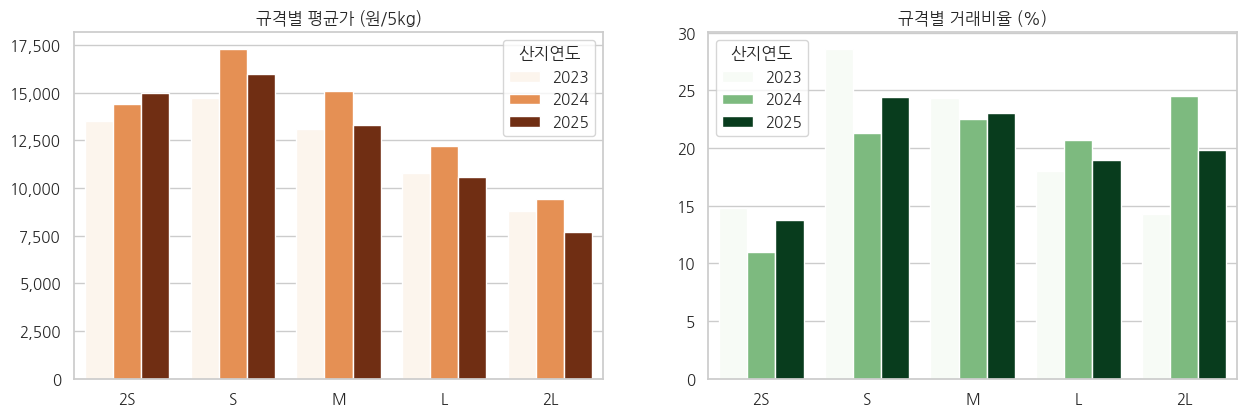

산지연도,2023,2024,2025
크기구분,,,
2S,"13,500.0","14,400.0","15,000.0"
S,"14,700.0","17,300.0","16,000.0"
M,"13,100.0","15,100.0","13,300.0"
L,"10,800.0","12,200.0","10,600.0"
2L,"8,800.0","9,400.0","7,700.0"


In [8]:
size = dfs["noji_size"].copy()
size["산지연도"] = parse_crop_year(size["산지연도"])
size_order = ["2S", "S", "M", "L", "2L"]
size["크기구분"] = pd.Categorical(size["크기구분"], categories=size_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=size, x="크기구분", y="평균가_원_5kg", hue="산지연도", palette="Oranges", ax=axes[0])
axes[0].set_title("규격별 평균가 (원/5kg)")
axes[0].yaxis.set_major_formatter(comma)
sns.barplot(data=size, x="크기구분", y="거래비율_퍼센트", hue="산지연도", palette="Greens", ax=axes[1])
axes[1].set_title("규격별 거래비율 (%)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
savefig("noji_size")
plt.show()

size.pivot_table(index="크기구분", columns="산지연도", values="평균가_원_5kg", observed=True)

In [9]:
# 규격 프리미엄: 2L 대비 가격 배수
premium = size.pivot_table(index="크기구분", columns="산지연도", values="평균가_원_5kg", observed=True)
(premium / premium.loc["2L"]).round(2)

산지연도,2023,2024,2025
크기구분,,,
2S,1.5,1.5,1.9
S,1.7,1.8,2.1
M,1.5,1.6,1.7
L,1.2,1.3,1.4
2L,1.0,1.0,1.0


**📝 관찰**
- 3개년 모두 **작은 과일(2S~S)이 비싸고 큰 과일(L~2L)이 쌉니다.** 노지온주는 "작을수록 맛있다"는 시장 인식이 가격에 그대로 반영되어 있습니다.
- 가장 비싼 규격은 S입니다. S의 가격은 2L의 약 1.7~2.1배이고, 2025년산에서 격차가 가장 큽니다.
- 2024년산은 2L 비중이 24.5%로 높았는데, 2025년산에는 S·2S 비중이 늘었습니다. 규격 구성의 변화가 2025년 단가를 지탱한 요인 중 하나일 수 있습니다(가설).

## 5. 도매시장별 거래량·가격 (FR-202)

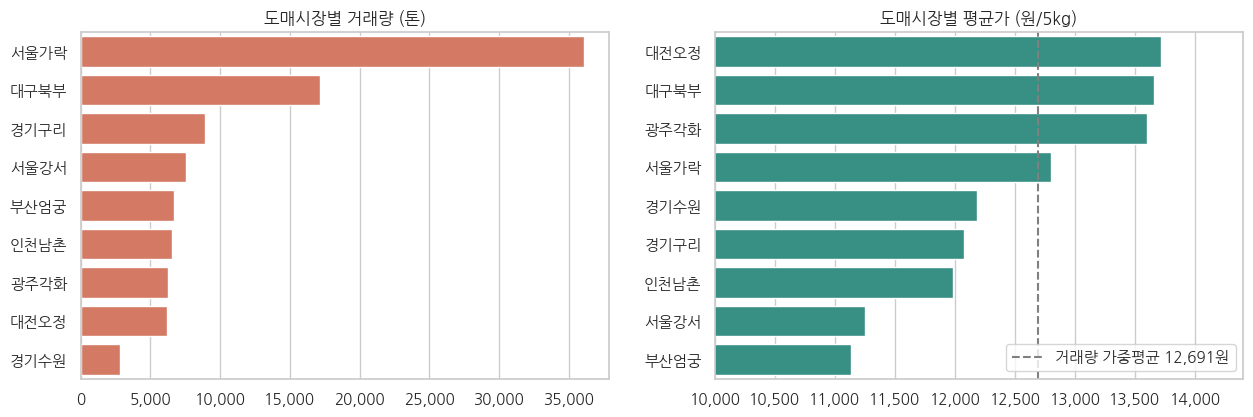

,품종구분,산지연도,도매시장,거래량_톤,평균가_원_5kg,거래비중_퍼센트
0,노지온주,2025년산,서울가락,36098,12805,36.8
1,노지온주,2025년산,대구북부,17179,13660,17.5
2,노지온주,2025년산,경기구리,8901,12077,9.1
3,노지온주,2025년산,서울강서,7522,11250,7.7
4,노지온주,2025년산,부산엄궁,6703,11135,6.8
5,노지온주,2025년산,인천남촌,6552,11986,6.7
6,노지온주,2025년산,광주각화,6237,13599,6.4
7,노지온주,2025년산,대전오정,6185,13717,6.3
8,노지온주,2025년산,경기수원,2826,12182,2.9


In [10]:
market = dfs["noji_market_2025"].sort_values("거래량_톤", ascending=False).reset_index(drop=True)
market["거래비중_퍼센트"] = market["거래량_톤"] / market["거래량_톤"].sum() * 100
avg_price = (market["평균가_원_5kg"] * market["거래량_톤"]).sum() / market["거래량_톤"].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=market, y="도매시장", x="거래량_톤", color="#e76f51", ax=axes[0])
axes[0].set_title("도매시장별 거래량 (톤)")
axes[0].xaxis.set_major_formatter(comma)

price_sorted = market.sort_values("평균가_원_5kg", ascending=False)
sns.barplot(data=price_sorted, y="도매시장", x="평균가_원_5kg", color="#2a9d8f", ax=axes[1])
axes[1].axvline(avg_price, ls="--", color="gray", label=f"거래량 가중평균 {avg_price:,.0f}원")
axes[1].set_title("도매시장별 평균가 (원/5kg)")
axes[1].xaxis.set_major_formatter(comma)
axes[1].set_xlim(10000, None)
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
savefig("noji_market_2025")
plt.show()

market

**📝 관찰**
- **서울가락 한 곳이 거래량의 약 37%** 를 차지하고, 대구북부(약 18%)가 그 뒤를 잇습니다.
- 평균가는 대전오정, 대구북부, 광주각화가 13,600원대로 가장 높고, 부산엄궁과 서울강서가 11,100~11,300원으로 가장 낮습니다. 시장 간 차이는 **약 2,600원/5kg(약 23%)** 입니다.
- 거래량이 가장 큰 서울가락의 평균가(12,805원)는 가중평균 수준입니다. 출하처를 다변화하면 단가를 높일 여지가 있을 수 있습니다(물류비 고려 필요).

## 6. 품종별 유통 비교 (FR-201)

> ⚠️ `*_증감률_퍼센트` 컬럼은 실제로는 **전년 대비 비율**입니다(101 = 전년의 101%, 즉 +1%). 컬럼명이 실제 의미와 다르니 주의하세요.

In [11]:
var = dfs["varieties_summary"].copy()
totals = var[var["세부품종"].isin(["계", "소계"])].set_index("대분류")
totals[["처리량_2025_톤", "단가_2025_원_kg", "조수입_2025_백만원", "처리량_2024_톤", "단가_2024_원_kg", "조수입_2024_백만원"]]

,처리량_2025_톤,단가_2025_원_kg,조수입_2025_백만원,처리량_2024_톤,단가_2024_원_kg,조수입_2024_백만원
대분류,,,,,,
하우스온주,"27,280.0",3622,98804,"27,036.0",3430,92725
월동온주,"27,708.0",2978,82523,"25,331.0",4432,112267
만감류,"113,985.0",3744,426752,"107,821.0",4184,451183


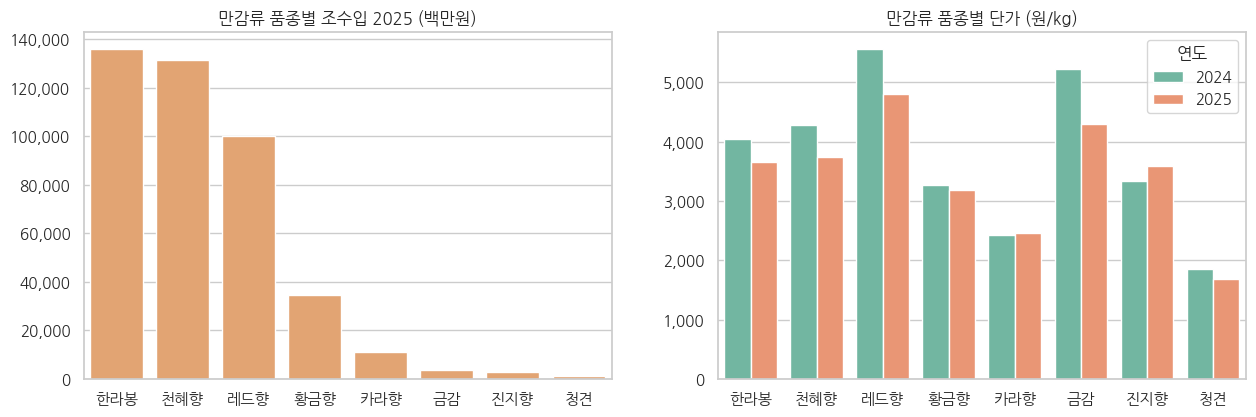

,세부품종,처리량_2025_톤,단가_2025_원_kg,조수입_2025_백만원,처리량_증감률_퍼센트,조수입_증감률_퍼센트
0,한라봉,"37,205.0",3657,136056,96,87
1,천혜향,"35,149.0",3740,131445,116,101
2,레드향,"20,839.0",4801,100050,116,100
3,황금향,"10,876.0",3191,34701,120,117
7,카라향,"4,430.0",2465,10921,118,120
6,금감,805.0,4294,3457,91,75
5,진지향,761.0,3593,2734,93,100
4,청견,769.0,1682,1294,97,88


In [12]:
mangam = drop_total_rows(var[var["대분류"] == "만감류"], "세부품종")
mangam = mangam[mangam["세부품종"] != "기타"].sort_values("조수입_2025_백만원", ascending=False)

long = mangam.melt(
    id_vars="세부품종",
    value_vars=["단가_2024_원_kg", "단가_2025_원_kg"],
    var_name="연도",
    value_name="단가_원_kg",
)
long["연도"] = long["연도"].str.extract(r"(\d{4})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=mangam, x="세부품종", y="조수입_2025_백만원", color="#f4a261", ax=axes[0])
axes[0].set_title("만감류 품종별 조수입 2025 (백만원)")
axes[0].yaxis.set_major_formatter(comma)
sns.barplot(data=long, x="세부품종", y="단가_원_kg", hue="연도", palette="Set2", ax=axes[1])
axes[1].set_title("만감류 품종별 단가 (원/kg)")
axes[1].yaxis.set_major_formatter(comma)
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
savefig("mangam_varieties")
plt.show()

mangam[["세부품종", "처리량_2025_톤", "단가_2025_원_kg", "조수입_2025_백만원", "처리량_증감률_퍼센트", "조수입_증감률_퍼센트"]]

**📝 관찰**
- 만감류에서는 **한라봉·천혜향·레드향 3개 품종이 조수입의 약 86%** 를 차지합니다.
- 단가는 레드향이 4,801원/kg으로 가장 높습니다. 다만 2025년에는 대부분의 품종에서 처리량이 늘고 단가가 떨어졌습니다(한라봉 -10%, 레드향 -14%).
- 황금향과 카라향은 처리량(+20%, +18%)과 조수입(+17%, +20%)이 함께 늘어난 **성장 품종**입니다.
- 월동온주는 2025년 단가가 4,432원에서 2,978원으로 **33% 떨어져** 조수입이 26% 줄었습니다. 원인을 확인해야 합니다.

## 7. 과수 생산량 추이 2015~2020 (FR-201)

> ⚠️ 같은 품종이 연도에 따라 다른 대분류로 분류되어 있습니다(예: `레드향`이 `기타`와 `만감류`에 모두 있고, `단감`도 마찬가지). 대분류 기준으로 집계하기 전에 품종 분류를 통일해야 합니다.

In [13]:
fruit = dfs["fruit_production"]

# 분류 불일치 점검: 한 품종이 여러 대분류에 속하는 경우
cnt = fruit.groupby("품종소분류")["품종대분류"].nunique()
fruit[fruit["품종소분류"].isin(cnt[cnt > 1].index)].sort_values(["품종소분류", "기준연도"])

,기준연도,품종대분류,품종소분류,생산면적(ha),생산량(톤)
6,2015,기타,기타,12,68
17,2015,만감류,기타,72,1902
30,2016,기타,기타,16,101
54,2017,기타,기타,22,138
78,2018,기타,기타,9,23
102,2019,기타,기타,11,52
126,2020,기타,기타,13,50
7,2015,기타,단감,74,551
41,2016,만감류,단감,65,379
65,2017,만감류,단감,56,457


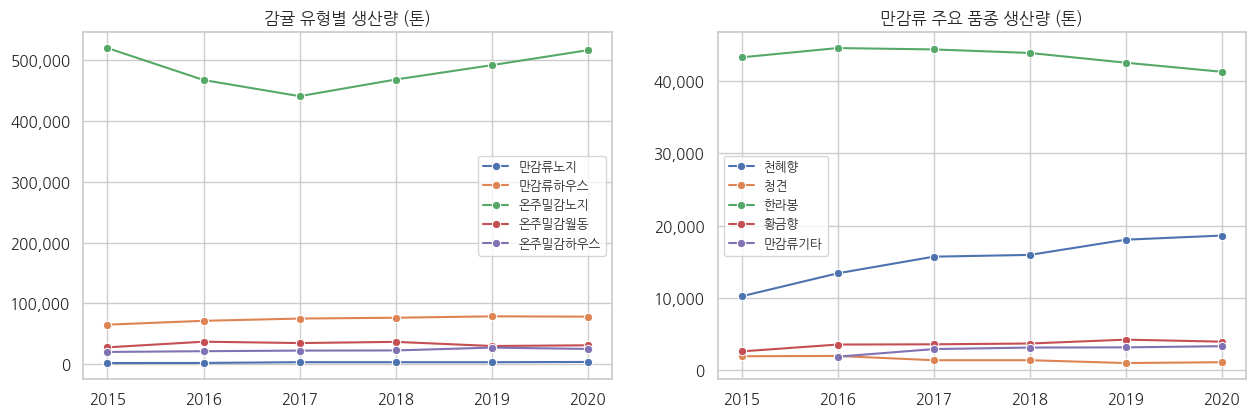

In [14]:
citrus = fruit[fruit["품종대분류"] == "감귤"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.lineplot(data=citrus, x="기준연도", y="생산량(톤)", hue="품종소분류", marker="o", ax=axes[0])
axes[0].set_title("감귤 유형별 생산량 (톤)")
axes[0].yaxis.set_major_formatter(comma)

top_mangam = fruit[fruit["품종대분류"] == "만감류"].groupby("품종소분류")["생산량(톤)"].sum().nlargest(5).index
sns.lineplot(
    data=fruit[fruit["품종소분류"].isin(top_mangam) & (fruit["품종대분류"] == "만감류")],
    x="기준연도", y="생산량(톤)", hue="품종소분류", marker="o", ax=axes[1],
)
axes[1].set_title("만감류 주요 품종 생산량 (톤)")
axes[1].yaxis.set_major_formatter(comma)
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend(fontsize=9)
savefig("fruit_production_trend")
plt.show()

In [15]:
# 생산성: 면적당 생산량 (톤/ha)
citrus_eff = citrus.assign(ha당_생산량=citrus["생산량(톤)"] / citrus["생산면적(ha)"])
citrus_eff.pivot_table(index="기준연도", columns="품종소분류", values="ha당_생산량").round(1)

품종소분류,만감류노지,만감류하우스,온주밀감노지,온주밀감월동,온주밀감하우스
기준연도,,,,,
2015,22.1,32.4,31.0,20.2,81.6
2016,23.4,33.1,28.1,27.9,76.3
2017,5.4,23.1,29.3,38.9,75.2
2018,5.6,23.3,31.4,39.5,71.3
2019,5.5,23.7,33.2,32.4,81.2
2020,6.4,23.3,35.0,33.2,69.9


**📝 관찰**
- 노지 온주밀감이 생산량의 압도적 다수를 차지합니다. 연도별 생산량 변동(해거리 현상 가능성)은 그래프에서 직접 확인해 보세요.
- 온주밀감 하우스는 면적당 생산량이 70~82톤/ha로 노지(28~35톤/ha)의 **2배 이상**입니다. 시설 투자비와 함께 비교하면 FR-302(품종 선택 가이드)의 근거가 됩니다.
- 만감류노지의 ha당 생산량이 2016년 23.4톤에서 2017년 5.4톤으로 급락합니다. 집계 기준이 바뀐 것으로 의심됩니다(Q4와 연관).
- ⚠️ 2016년 이후 `레드향`이 `기타`로 분류되어 있어서, 오른쪽 '만감류 주요 품종' 그래프에는 **레드향이 빠져 있습니다.** Q4 매핑을 적용한 뒤 다시 그려야 합니다.
- ⚠️ 2015~2020년 데이터라서 2021~2025년 유통 데이터와 기간이 겹치지 않습니다. 최신 생산 통계를 더 확보해야 합니다.

### 7-1. 보정 후 다시 그리기 (Q4 정제 적용)

`interim/fruit_production_clean.csv`는 레드향·단감의 뒤바뀐 대분류를 바로잡은 데이터입니다(`clean_quality.clean_fruit_production`).
이제 오른쪽 그래프에 **레드향이 들어갑니다.**

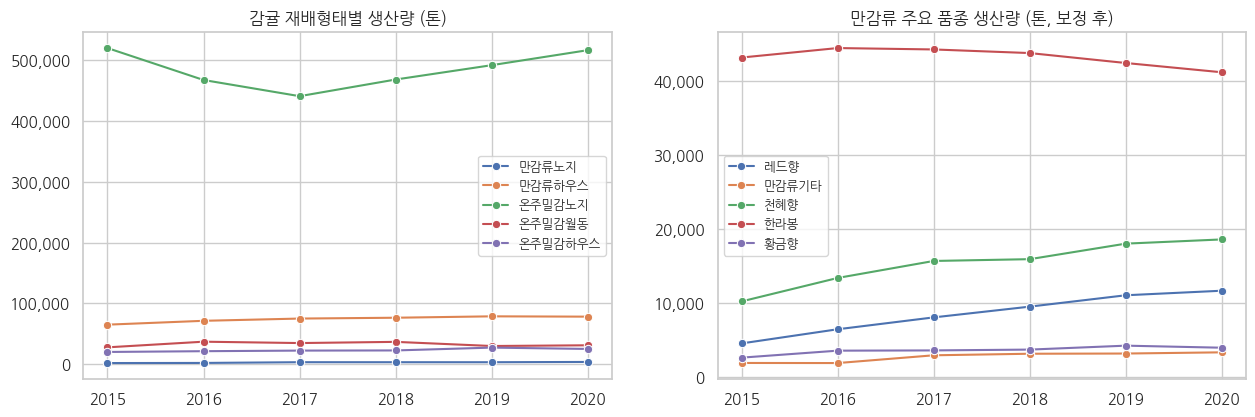

In [16]:
from jeju_citrus.config import INTERIM_DIR

fruit_clean = pd.read_csv(INTERIM_DIR / "fruit_production_clean.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.lineplot(
    data=fruit_clean[fruit_clean["집계수준"] == "감귤_재배형태"],
    x="연도", y="생산량_톤", hue="품종", marker="o", ax=axes[0],
)
axes[0].set_title("감귤 재배형태별 생산량 (톤)")
mangam = fruit_clean[fruit_clean["집계수준"] == "만감류_품종"]
top5 = mangam.groupby("품종")["생산량_톤"].sum().nlargest(5).index
sns.lineplot(data=mangam[mangam["품종"].isin(top5)], x="연도", y="생산량_톤", hue="품종", marker="o", ax=axes[1])
axes[1].set_title("만감류 주요 품종 생산량 (톤, 보정 후)")
for ax in axes:
    ax.yaxis.set_major_formatter(comma)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend(fontsize=9)
savefig("fruit_production_trend_clean")
plt.show()

## 8. 제주 특용작물 (참고)

감귤과 직접 관련된 데이터는 아니지만, 대체·병행 작목을 검토할 때 참고하기 위해 살펴봅니다.

기간: 2010 ~ 2023 / 품목 수: 92


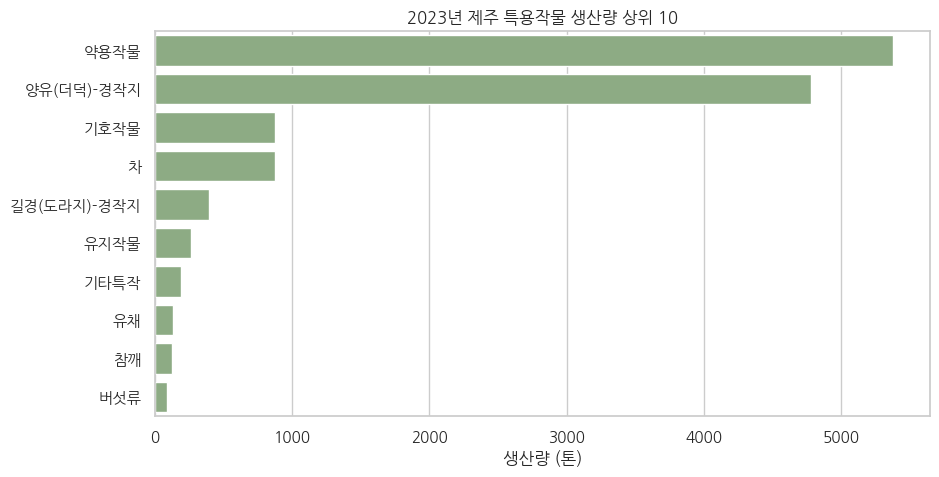

In [17]:
crops = dfs["jeju_special_crops"]
print("기간:", crops["기준 연도"].min(), "~", crops["기준 연도"].max(), "/ 품목 수:", crops["품명"].nunique())

# '기타'는 같은 연도에 여러 행이 존재 → 합산
by_crop = crops.groupby(["기준 연도", "품명"], as_index=False)[["농가수[호]", "재배면적[ha]", "생산량[M/T]"]].sum()
latest = by_crop[by_crop["기준 연도"] == by_crop["기준 연도"].max()].nlargest(10, "생산량[M/T]")

ax = sns.barplot(data=latest, y="품명", x="생산량[M/T]", color="#8ab17d")
ax.set_title(f"{by_crop['기준 연도'].max()}년 제주 특용작물 생산량 상위 10")
ax.set_xlabel("생산량 (톤)")
ax.set_ylabel("")
plt.show()

In [18]:
# 이상치 점검: 단수(kg/10a) 분포
crops["단수[kg/10a]"].describe(percentiles=[0.5, 0.9, 0.99])

count      752.0
mean       254.8
std        868.1
min          0.0
50%          0.0
90%        792.0
99%      1,919.0
max     21,008.0
Name: 단수[kg/10a], dtype: float64

**📝 관찰**
- `품명 = 기타`는 같은 연도에 여러 행이 있으므로 품목별로 볼 때는 합산하거나 제외해야 합니다.
- `단수[kg/10a]`는 결측치가 6건이고, **값의 절반 이상(57%)이 0**입니다. 극단적으로 큰 값(최대 21,008)도 있습니다. 0이 '미수확'을 뜻하는지 '미집계'를 뜻하는지, 큰 값이 단위 오류인지 확인이 필요합니다.
- 중복행이 1건 있습니다.

### 8-1. 보정 후 다시 그리기 (Q5 정제 적용)

위 그래프의 `약용작물`·`기호작물`·`유지작물`·`기타특작`·`버섯류`는 개별 작물이 아니라 **2023년에만 있는 품목군 소계 행**이었습니다.
`interim/jeju_special_crops_clean.csv`에서는 소계·중복·미재배 행을 뺐으므로 실제 작물 순위가 나옵니다.

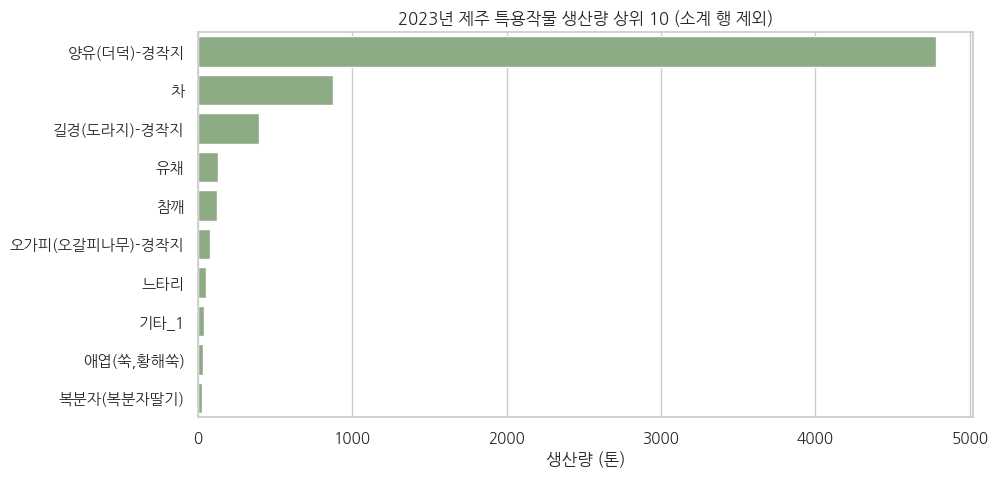

In [19]:
crops_clean = pd.read_csv(INTERIM_DIR / "jeju_special_crops_clean.csv", encoding="utf-8-sig")
year = crops_clean["연도"].max()
top10 = crops_clean[crops_clean["연도"] == year].nlargest(10, "생산량_톤")
ax = sns.barplot(data=top10, y="품명", x="생산량_톤", color="#8ab17d")
ax.set_title(f"{year}년 제주 특용작물 생산량 상위 10 (소계 행 제외)")
ax.set_xlabel("생산량 (톤)")
ax.set_ylabel("")
savefig("special_crops_top10_clean")
plt.show()

## 9. 정리 및 다음 단계

### 데이터 품질 이슈 (→ `docs/requirements_spec.md` §4)
| # | 데이터 | 이슈 | 처리 방안 |
| --- | --- | --- | --- |
| Q1 | noji_*, yearly | 연도가 `'2025년산'` 문자열 | `parse_crop_year()` ✅ |
| Q2 | monthly, varieties | `계`/`소계` 합계 행 혼재 | `drop_total_rows()` ✅ |
| Q3 | varieties_summary | `증감률` 컬럼이 실제로는 전년 대비 비율(%) | 컬럼명 변경 또는 -100 변환 |
| Q4 | fruit_production | 같은 품종이 연도별로 다른 대분류에 속함 | 품종 분류 매핑 테이블 작성 |
| Q5 | jeju_special_crops | `기타` 중복 행, 중복행 1건, 단수 결측 6건·0값 57%·이상치 | 중복 제거, 0/결측 의미 확인, 이상치 기준 정의 |
| Q6 | 전체 | 생산 통계(2015~2020)와 유통 통계(2021~2025)의 기간 불일치 | 최신 통계 수집 |

### 다음에 같이 할 것
- [ ] Q3~Q5 정제 로직을 `src/jeju_citrus/data/`로 옮기고 `data/interim/`에 저장
- [ ] `02_price_analysis.ipynb`: 품종·규격·시장을 한 기준(원/kg)으로 통일한 가격 비교
- [ ] 기상 데이터(기온·강수량·일조) 수집 → `data/external/` (FR-203)
- [ ] 쓸모 있는 그래프는 `src/jeju_citrus/visualization/`에 함수로 정리